# Single synonymous codon exchanges

- 27.10.2025
- For model validation
- https://pmc.ncbi.nlm.nih.gov/articles/PMC4595056/#ack1
- Findet man mit dem Modell einen Unterschied zwischen den Sequenzversionen, der die gezeigten Effekte auf die Atmung, Wachstum und Produktion im Paper erklären kann?
- E. coli mit Bacillus subtilis Enzym BSLA
- Paper states that tRNA availabily could be the issue but they cant measure it and say its not important

To Dos:
- Find LipA sequence that agrees with the numbering in the paper
- Load Fasta
- Generate versions of the gene with synonymous codon exchanges
- Calcualte translation rates
- Print tRNA concentrations
- Print translation elongation profile
- Calculate an compare absolute protein amounts
- Efficiency factor analysis

## Load packages

In [15]:
# packages
include("packages.jl")

🔧 Julia started with 8 threads


parameters (generic function with 1 method)

## Generate sequences

### Load fasta

In [16]:
# import BSLA van Pouderoyen 2001
seq_file = "BSLAvP.fa"
seqs_to_use 	    = (1,1) 
seqs, seq_names = seqs_import_transcripts(seq_file,seqs_to_use) # Function that transforms DNA Sequence into mRNA, amino acids and codons
BSLA_vP = seqs["BSLA"]

✅ Successfully loaded 1 sequences


Main.txtl_types.SequenceData(GCTGAACACAATCCAGTCGTTATGGTTCACGGTATTGGA…ATTAAAGAAGGGCTGAACGGCGGGGGCCAGAATACGAAT, GCUGAACACAAUCCAGUCGUUAUGGUUCACGGUAUUGGA…AUUAAAGAAGGGCUGAACGGCGGGGGCCAGAAUACGAAU, AEHNPVVMVHGIGGASFNFAGIKSYLVSQGWSRDKLYAV…LDGARNVQIHGVGHIGLLYSSQVNSLIKEGLNGGGQNTN, LongSequence{RNAAlphabet{2}}[GCU, GAA, CAC, AAU, CCA, GUC, GUU, AUG, GUU, CAC  …  GGG, CUG, AAC, GGC, GGG, GGC, CAG, AAU, ACG, AAU])

### Arginine107 sequence versions

In [17]:
# Arginine strains
amino_acids = BSLA_vP.AA1
codons		= BSLA_vP.Codon
pos_arg	 	= 107

println(
	"Arginine is on position$pos_arg with $(amino_acids[pos_arg]) and has the codon $(codons[pos_arg])."
)

arginine_codons = ["CGT","AGA","AGG","CGA","CGC","CGG"] # Codons that translate to arginine 
arginine_codons = [LongDNA{2}(i) for i in arginine_codons] # Convert to BioSequences type RNA 

Arg107 = Dict(					# Dictionary with 6 BSLA versions with a synonymous codon exchange for Arginine107
	:CGT	=> codons,
	:AGA	=> copy(codons),
	:AGG	=> copy(codons),
	:CGA	=> copy(codons),
	:CGC	=> copy(codons),
	:CGG	=> copy(codons)
)

for codon in arginine_codons 	# Einfügen des synonymen codon austauschs
	Arg107[Symbol(codon)][pos_arg] = codon
end


Arginine is on position107 with R and has the codon CGU.


### Leucine143 sequence versions

In [18]:
# Leucine strains
pos_leu 	= 143

println(
	"Leucine is on position $pos_leu with $(amino_acids[pos_leu]) and has the codon $(codons[pos_leu])."
)


leucine_codons = ["TTA","TTG","CTT","CTC","CTA","CTG"] # Codons that translate to arginine 
leucine_codons = [LongDNA{2}(i) for i in leucine_codons] # Convert to BioSequences type RNA 


Leu143 = Dict(					# Dictionary with 6 BSLA versions with a synonymous codon exchange for Arginine107
	:TTA	=> codons,
	:TTG	=> copy(codons),
	:CTT	=> copy(codons),
	:CTC	=> copy(codons),
	:CTA	=> copy(codons),
	:CTG	=> copy(codons)
)

for codon in leucine_codons 	# Einfügen des synonymen codon Austauschs
	Leu143[Symbol(codon)][pos_leu] = codon
end

Leucine is on position 143 with L and has the codon UUA.


### Save fasta files

In [19]:
Arg107_headers = Dict(					# Dictionary with 6 BSLA versions with a synonymous codon exchange for Arginine107
	:CGT	=> "Arg107CGT BSLA van Pouderoyen 2001 WT",
	:AGA	=> "Arg107AGA BSLA van Pouderoyen 2001",
	:AGG	=> "Arg107AGG BSLA van Pouderoyen 2001",
	:CGA	=> "Arg107CGA BSLA van Pouderoyen 2001",
	:CGC	=> "Arg107CGC BSLA van Pouderoyen 2001",
	:CGG	=> "Arg107CGG BSLA van Pouderoyen 2001"
)

Arg107_files = Dict(			# names for fasta file for every sequence version 
	:CGT	=> "Arg107CGT",
	:AGA	=> "Arg107AGA",
	:AGG	=> "Arg107AGG",
	:CGA	=> "Arg107CGA",
	:CGC	=> "Arg107CGC",
	:CGG	=> "Arg107CGG"
)

for codon in arginine_codons	# Generation of fasta files for every sequence version
	codon 		= Symbol(codon)
	filename 	= "../data/validation/rahmen_2015/"*Arg107_files[codon]*".fasta"

	seq_vector 	= Arg107[codon]
	rna_seq		= reduce(*, seq_vector)
	seq 		= convert(LongDNA{2}, rna_seq)

	header 		= Arg107_headers[codon]

	open(FASTA.Writer, filename; width=60) do writer
    	write(writer, FASTA.Record(header, seq))
	end


end

In [20]:
Leu143_headers = Dict(					# Dictionary with 6 BSLA versions with a synonymous codon exchange for Arginine107
	:TTA	=> "Leu143TTA BSLA van Pouderoyen 2001 WT",
	:TTG	=> "Leu143TTG BSLA van Pouderoyen 2001",
	:CTT	=> "Leu143CTT BSLA van Pouderoyen 2001",
	:CTC	=> "Leu143CTC BSLA van Pouderoyen 2001",
	:CTA	=> "Leu143CTA BSLA van Pouderoyen 2001",
	:CTG	=> "Leu143CTG BSLA van Pouderoyen 2001"
)

Leu143_files = Dict(			# names for fasta file for every sequence version 
	:TTA	=> "Leu143TTA",
	:TTG	=> "Leu143TTG",
	:CTT	=> "Leu143CTT",
	:CTC	=> "Leu143CTC",
	:CTA	=> "Leu143CTA",
	:CTG	=> "Leu143CTG"
)

for codon in leucine_codons	# Generation of fasta files for every sequence version
	codon 		= Symbol(codon)
	filename 	= "../data/validation/rahmen_2015/"*Leu143_files[codon]*".fasta"

	seq_vector 	= Leu143[codon]
	rna_seq		= reduce(*, seq_vector)
	seq 		= convert(LongDNA{2}, rna_seq)

	header 		= Leu143_headers[codon]

	open(FASTA.Writer, filename; width=60) do writer
    	write(writer, FASTA.Record(header, seq))
	end


end

In [23]:
Leu143_files[:TTA]

"Leu143TTA"

## Calculate translation rates

In [ ]:
# Sequences 
sequence_file	    = "Ecoli_K12_MG1655_geneset_with_rahmen_2015.fa"    # "lacS_background.fa"
hybrid_file		    = "lacS.txt"
seqs_to_use 	    = (1,2323)                                 # Range of sequences in Fasta file. Takes all sequences from sequence a to sequence b
num_background_genes = 10

# initialization of data containers
scale = txtl_types.init_scale()         # struct that makes it possible to influence rates by scaling them

µ = 1                    # A growth rate (0.1 to 1.8) can be chosen and the proteins of the TXTL machinery will be tuned according to that growth rate and the processivity of the RNA polymerase

## flags for efficiency factors
positive_aminoacid	= true 
anti_shinedalgarno	= false      # If no hybridization file is available put flag to false. We apply the intaRNA program's intarna function (q: aSD, t: sequence, SeedBP: 5, out: tMinE) to generate a hybridization profile along the sequence. Link to the website: https://rna.informatik.uni-freiburg.de/IntaRNA/Input.jsp;jsessionid=2AE257E91E7276283F22CD77A5A8AA03
dynamic_efficiency	= true 
save_data           = false

flags = txtl_types.flags(positive_aminoacid, anti_shinedalgarno, dynamic_efficiency)

# Data import --------
mRNA 		= to_DataFrame(readmatrix("../data/input/mRNA_concentrations.xlsx", "mRNA_concentration", "A1:B2414")) # mRNA_concentration_high_cell_v
mRNA.mRNA 	= Float64.(mRNA.mRNA);

background_genes = String.(first(mRNA.gene, num_background_genes));

solutions   = []
params_list  = []


### Arginine

In [ ]:
for sequence_version in arginine_codons

	codon 				= Symbol(sequence_version)
	heterologous_genes 	=  [Arg107_files[codon]]
    genes = vcat(background_genes, heterologous_genes)
    mRNA_welch = subset(mRNA, :gene => ByRow(in(genes)));

    solution, p_parallel 	= competition_model(genes, µ, sequence_file, hybrid_file, flags, seqs_to_use, mRNA_welch)

	push!(solutions, solution)
	push!(params_list, p_parallel)

end

Arg107CGT
Arg107AGA
Arg107AGG
Arg107CGA
Arg107CGC
Arg107CGG


### Leucine

In [ ]:
for sequence_version in leucine_codons

	codon 				= Symbol(sequence_version)
	heterologous_genes 	=  [Leu143_files[codon]]
    genes = vcat(background_genes, heterologous_genes)
    mRNA_welch = subset(mRNA, :gene => ByRow(in(genes)));

    solution, p_parallel 	= competition_model(genes, µ, sequence_file, hybrid_file, flags, seqs_to_use, mRNA_welch)

	push!(solutions, solution)
	push!(params_list, p_parallel)

end

Leu143TTA
Leu143TTG
Leu143CTT
Leu143CTC
Leu143CTA
Leu143CTG


## Smoothed elongation profile

In [133]:
# packages
include("01_packages.jl")

# efficiency factors
V_TL_EL_list         = []
efficiencies_list    = []
pos_amino_list       = []
dyn_efac_list        = []

y_rib_list           = []

V_EL_smooth_list     = []
h1_list              = []
V_ELO_list           = []

for i in 1:length(tags_list)

    sol     = solutions[i]
    tags    = tags_list[i]

    # efficiency factors
    V_TL_EL, efficiencies, pos_amino, dyn_efac = four_V_TL_EL(sol[end], tags)
    y_rib = sol[end][139:end]
    push!(V_TL_EL_list, V_TL_EL)
    push!(efficiencies_list, efficiencies)
    push!(pos_amino_list, pos_amino)
    push!(dyn_efac_list, dyn_efac)

    # ribosome concentrations
    push!(y_rib_list, y_rib)

    # V_TL_EL divided by ribosome concentration and smoothed with sliding window
    V_EL_smooth, h1, V_ELO = V_EL_smooth_analyze_parallel_data(tags, V_TL_EL, y_rib)
    push!(V_EL_smooth_list, V_EL_smooth)
    push!(h1_list, h1)
    push!(V_ELO_list, V_ELO)

end

In [171]:
using Plots 
using Measures

default(
	linewidth 	= 3,
	guidefont 	= font(26),
	tickfont 	= font(18),
	titlefont	= font(18)

	)


### Arginine

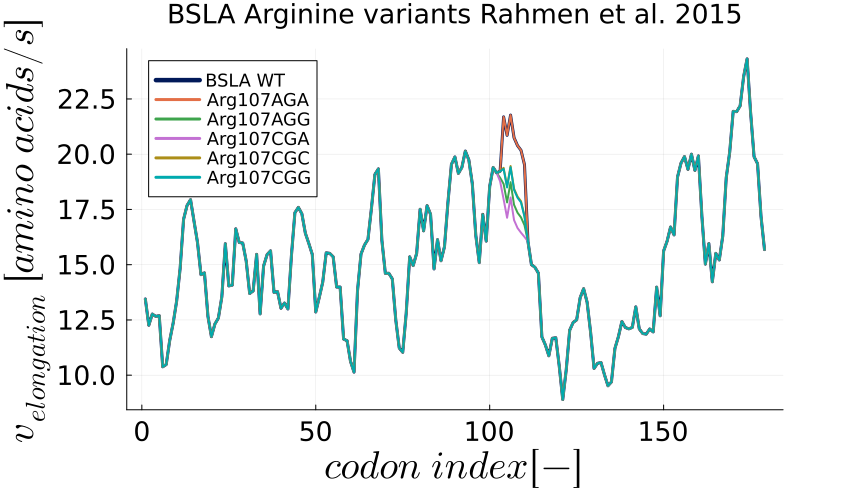

In [173]:
plt = plot(V_EL_smooth_list[1], xlabel = L"codon\ index [-]", 
	ylabel = L"v_{elongation}\ [amino\ acids/s]", label = "BSLA WT",
	size = (850, 500), left_margin = 5mm, bottom_margin = 7mm, top_margin = 5mm, right_margin = 15mm,
	legend=:topright, legendfontsize = 18, linecolor = farben.marine, title = "BSLA Arginine variants Rahmen et al. 2015")

	for (idx, codon) in enumerate(arginine_codons[2:end])
		plot!(plt, V_EL_smooth_list[idx], label = Arg107_files[Symbol(codon)], linewidth = 2)
	end

	plot!(plt, legendfont = font(12), legend = :topleft)

	display(plt)

In [174]:
foldername 	= joinpath(pwd(), "plots") # Pfad zum neuen Ordner im aktuellen Arbeitsverzeichnis
filename 	= "Elongation_profile_BSLA_Arginine_variants_Rahmen_2015" 
filepath = joinpath(foldername, filename)
savefig(filepath)

"z:\\users\\ac135292\\04_Models\\P002-Transcription_Translation\\Julia\\08_model_validation\\plots\\Elongation_profile_BSLA_Arginine_variants_Rahmen_2015.png"

### Leucine

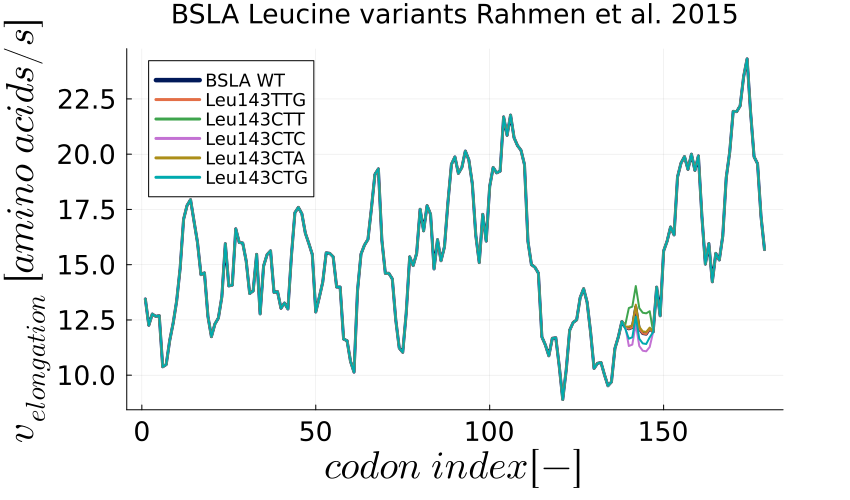

In [175]:
plt = plot(V_EL_smooth_list[7], xlabel = L"codon\ index [-]", 
	ylabel = L"v_{elongation}\ [amino\ acids/s]", label = "BSLA WT",
	size = (850, 500), left_margin = 5mm, bottom_margin = 7mm, top_margin = 5mm, right_margin = 15mm,
	legend=:topright, legendfontsize = 18, linecolor = farben.marine, title = "BSLA Leucine variants Rahmen et al. 2015")

	for (idx, codon) in enumerate(leucine_codons[2:end])
		plot!(plt, V_EL_smooth_list[idx+6], label = Leu143_files[Symbol(codon)], linewidth = 2)
	end

	plot!(plt, legendfont = font(12), legend = :topleft)

	display(plt)

In [176]:
foldername 	= joinpath(pwd(), "plots") # Pfad zum neuen Ordner im aktuellen Arbeitsverzeichnis
filename 	= "Elongation_profile_BSLA_Leucine_variants_Rahmen_2015" 
filepath = joinpath(foldername, filename)
savefig(filepath)

"z:\\users\\ac135292\\04_Models\\P002-Transcription_Translation\\Julia\\08_model_validation\\plots\\Elongation_profile_BSLA_Leucine_variants_Rahmen_2015.png"

In [178]:
c_end_ddc = 8.57997e-6 # mg/mL
c_end_ddc *= 1000 # µg/mL



0.008579970000000001